# Predikcija odliva klijenata banaka - Stablo olučivanja

In [1]:
# Uključivanje potrebnih biblioteka
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, \
    f1_score
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.sandbox.predict_functional import predict_functional


In [3]:
# Učitavanje detaseta
df = pd.read_csv('data/bank.csv', na_values=['-', ' ', ''])

display(df.head())
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Surname             4897 non-null   str    
 1   CreditScore         4898 non-null   int64  
 2   Geography           4896 non-null   str    
 3   Gender              4898 non-null   str    
 4   Age                 4895 non-null   float64
 5   Tenure              4898 non-null   int64  
 6   Balance             4898 non-null   float64
 7   NumOfProducts       4898 non-null   int64  
 8   HasCrCard           4898 non-null   int64  
 9   IsActiveMember      4898 non-null   int64  
 10  EstimatedSalary     4898 non-null   float64
 11  Exited              4898 non-null   int64  
 12  Satisfaction.Score  4898 non-null   int64  
 13  Card.Type           4898 non-null   str    
 14  Point.Earned        4898 non-null   int64  
dtypes: float64(3), int64(8), str(4)
memory usage: 574.1 KB


In [4]:
# Kreiranje varijable Stayed na osnovu vrednosti varijable Exited
#Provera da li ima NA u Exited
print("Exited ima NA vrednosti:", df['Exited'].isna().any())
df['Stayed'] = np.where(df['Exited'] == 0, 'Yes', 'No')   # pozitivna klasa je Yes
#Izlazna varijabla se prebacuje u 1 i 0 zato što DecisionTreeClassifier iz scikit-learn biblioteke radi samo sa numeričkim tipovima podataka
df['Stayed'] = df['Stayed'].map({'Yes': 1, 'No': 0})

#Uklanjanje varijable Exited jer je korišćena za kreiranje izlazne varijable
df.drop(columns='Exited', inplace=True)


Exited ima NA vrednosti: False


In [ ]:
#valjda moze ovo da se uradi u samo jednoj liniji koda sa
# Ako si siguran u logiku:
# df['Stayed'] = (df['Exited'] == 0).astype(int)

In [6]:
#Kreiranje podskupa
#Zamena nedostajućih vrednosti
print(df['Age'].isna().sum())
df['Age'].fillna(df['Age'].median())

df = df[df['Age'] <= 87]
print(df['Age'].describe())

0
count    4894.000000
mean       38.968124
std        10.591644
min        18.000000
25%        32.000000
50%        37.000000
75%        44.000000
max        85.000000
Name: Age, dtype: float64


In [8]:
df_subset = df[df['Age'] <= 87]
print(df_subset['Age'].describe())

count    4894.000000
mean       38.968124
std        10.591644
min        18.000000
25%        32.000000
50%        37.000000
75%        44.000000
max        85.000000
Name: Age, dtype: float64


### Zamena nedostajućih vrednosti

In [9]:
print("Neodostajuće vrednosti:\n", df.isna().sum())
#Varijable Surname i Geography imaju nedostajuće vrednosti
#Varijablu Surname ćemo kasnije izbaciti, jer nije relevantna za predviđanje izlazne varijable

Neodostajuće vrednosti:
 Surname               1
CreditScore           0
Geography             2
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0
Stayed                0
dtype: int64


In [10]:
#Nedostajuće vrednosti varijable Geography zamenjujemo sa najčešćom vrednošću
df['Geography'] = df['Geography'].fillna(df['Geography'].mode()[0])
df.Geography.isnull().sum()

np.int64(0)

### Procena značajnosti atributa za uključivanje u model

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4894 entries, 1 to 4897
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Surname             4893 non-null   object 
 1   CreditScore         4894 non-null   int64  
 2   Geography           4894 non-null   object 
 3   Gender              4894 non-null   object 
 4   Age                 4894 non-null   float64
 5   Tenure              4894 non-null   int64  
 6   Balance             4894 non-null   float64
 7   NumOfProducts       4894 non-null   int64  
 8   HasCrCard           4894 non-null   int64  
 9   IsActiveMember      4894 non-null   int64  
 10  EstimatedSalary     4894 non-null   float64
 11  Satisfaction.Score  4894 non-null   int64  
 12  Card.Type           4894 non-null   object 
 13  Point.Earned        4894 non-null   int64  
 14  Stayed              4894 non-null   int64  
dtypes: float64(3), int64(8), object(4)
memory usage: 611.8+ KB


In [11]:
#Varijabla surname se uklanja jer nije značajna za procenu odliva klijenta
df = df.drop(columns=['Surname'])

In [16]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='CreditScore', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

#Ne treba zadržati CreditScore jer se raspodele za varijablu Stayed (Yes/No) gotovo potpuno preklapaju i atribut ne doprinosi razdvajanju klasa.
df.drop(columns=['CreditScore'], inplace=True)

<Figure size 600x400 with 0 Axes>

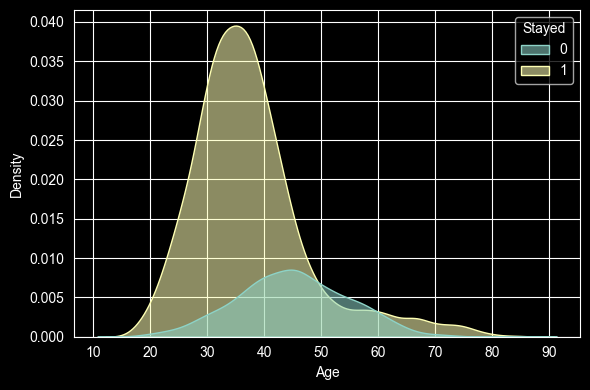

In [18]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='Age', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

# Na grafiku se može videti da se vrednosti varijable Age razlikuju u pogledu izlazne varijable. Varijabla Age će se uključiti u model

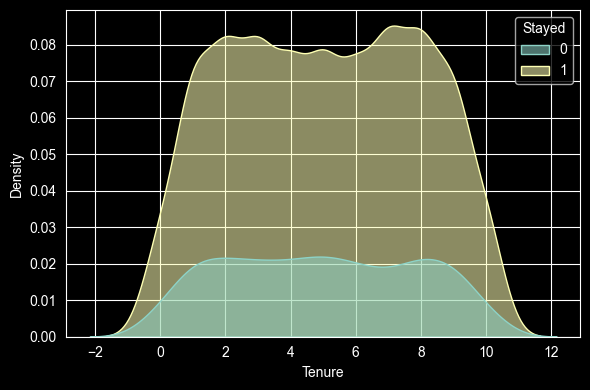

In [22]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='Tenure', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

#Ne treba zadržati varijablu Tenure jer se raspodele za varijablu Stayed (Yes/No) gotovo potpuno preklapaju i atribut ne doprinosi razdvajanju klasa.
df.drop(columns=['Tenure'], inplace=True)

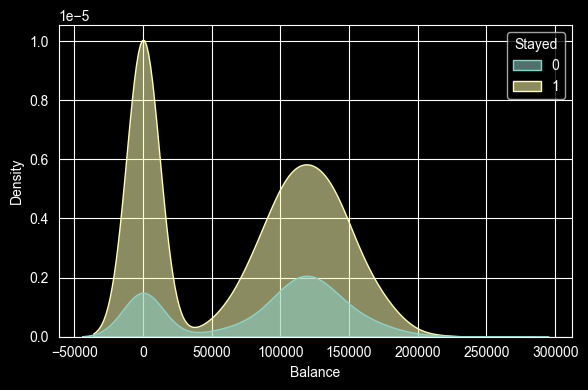

In [21]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='Balance', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

#Na grafiku se može videti da se raspodela varijable Balance razlikuje za različite klase izlazne promenljive, pa će varijabla Balance biti uključena u model.

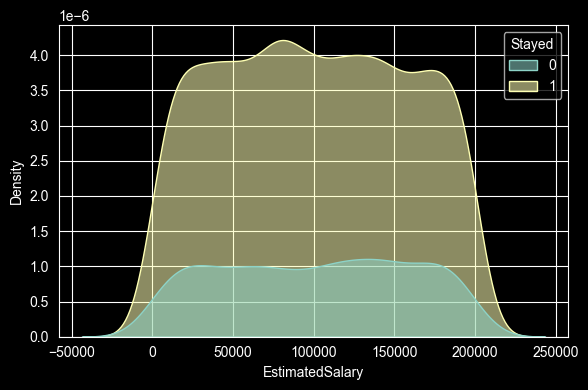

In [20]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='EstimatedSalary', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

# EstimatedSalary ne treba zadržati jer se gustinske krive za obe klase dosta poklapaju i atribut ne može doprineti razdvajanju klasa izlazne varijable.
df.drop(columns=['EstimatedSalary'], inplace=True)

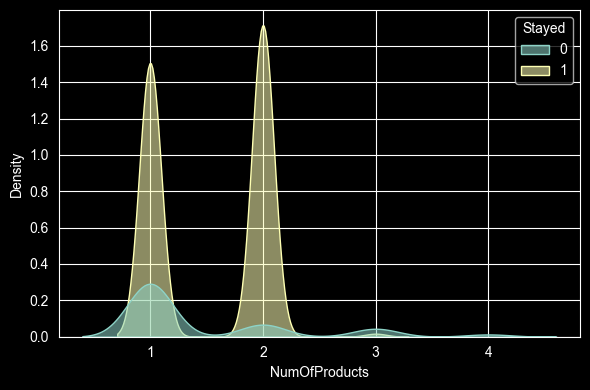

In [23]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='NumOfProducts', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

#NumOfProducts može doprineti proceni razlikovanja klijenata koji ostaju od onih koji odlaze iz banke.

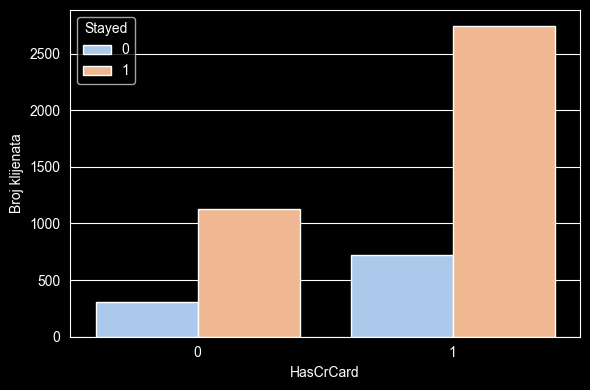

In [19]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='HasCrCard', hue='Stayed', palette='pastel')
plt.xlabel('HasCrCard')
plt.ylabel('Broj klijenata')
plt.legend(title='Stayed')
plt.tight_layout()
plt.show()

#HasCrCard ne treba zadržati jer se proporcije klijenata sa i bez kreditne kartice među onima koji ostaju i odlaze gotovo poklapaju i ne doprinosi razdvajanju klasa.
df.drop(columns=['HasCrCard'], inplace=True)

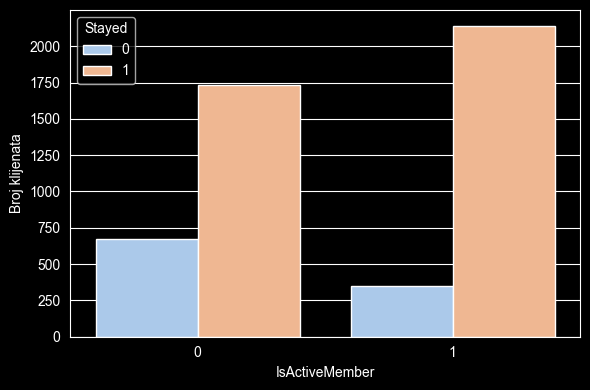

In [24]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='IsActiveMember', hue='Stayed', palette='pastel')
plt.xlabel('IsActiveMember')
plt.ylabel('Broj klijenata')
plt.legend(title='Stayed')
plt.tight_layout()
plt.show()

#Na grafiku se može videti da se proporcije klijenata sa IsActiveMember=0 i IsActiveMember=1 razlikuju u odnosu na izlaznu promenljivu, pa će varijabla IsActiveMember biti uključena u model.

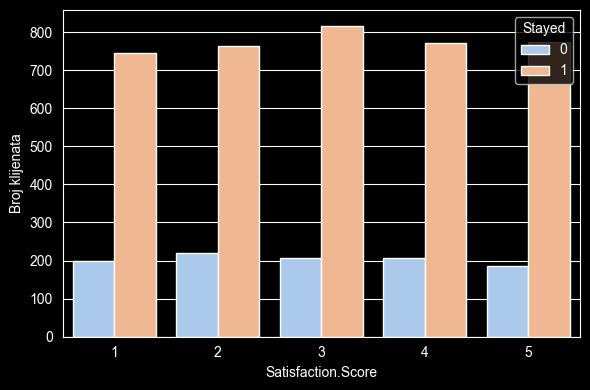

In [25]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Satisfaction.Score', hue='Stayed', palette='pastel')
plt.xlabel('Satisfaction.Score')
plt.ylabel('Broj klijenata')
plt.legend(title='Stayed')
plt.tight_layout()
plt.show()

#Na bar plotu se vidi da se proporcije „stayed“ i „not stayed“ gotovo podudaraju za sve nivoe Satisfaction.Score, pa se ta varijabla neće uključiti u model.
df.drop(columns=['Satisfaction.Score'], inplace=True)

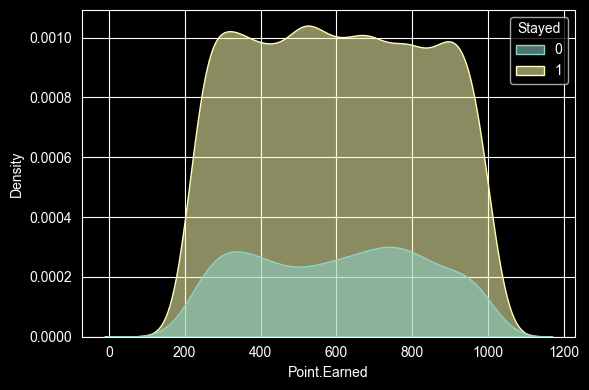

In [26]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='Point.Earned', hue='Stayed', fill=True, alpha=0.55)
plt.tight_layout()
plt.show()

# Point.Earned ne treba zadržati jer se gustinske krive za obe klase dosta poklapaju i atribut ne može doprineti razdvajanju klasa izlazne varijable.
df.drop(columns=['Point.Earned'], inplace=True)

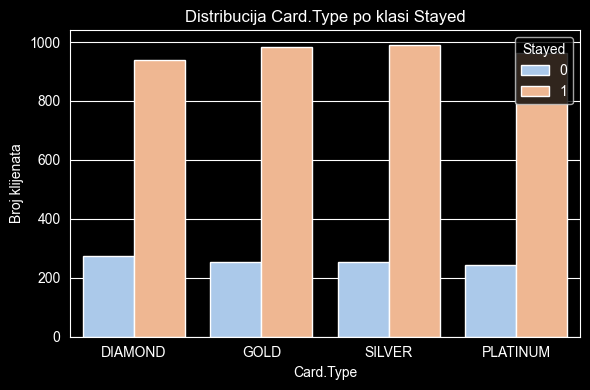

In [27]:
# Bar plotovi za Geography, Gender i Card.Type grupisani po Stayed
for col in ['Geography', 'Gender', 'Card.Type']:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x=col, hue='Stayed', palette='pastel')
    plt.title(f'Distribucija {col} po klasi Stayed')
    plt.xlabel(col)
    plt.ylabel('Broj klijenata')
    plt.legend(title='Stayed')
    plt.tight_layout()
    plt.show()

In [28]:
#Geography treba zadržati jer se proporcije za varijablu Stayed značajno razlikuju po zemljama (npr. klijenti iz Francuske ostaju u mnogo većem delu nego oni iz Španije i Nemačke).
#IsActiveMember pokazuje jasnu razliku u proporcijama Stayed/Not stayed i treba je zadržati, dok HasCrCard nema značajan doprinos.
df.drop(columns=['Card.Type'], inplace=True)

### Priprema podataka za uključivanje u model - Prebacivanje u numeric

In [29]:
df.select_dtypes(include=object).info()

/var/folders/sl/rg6h9x412vq0p9lz59yc_hlm0000gn/T/ipykernel_82357/210664501.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include=object).info()


In [30]:
#Druge karakter varijable se procenjuju na osnovu njihovog tipa (ordinalna ili kategorička), broja različitih vrednosti i raspodele vrednosti
df_vars = df.select_dtypes(include=object).columns.tolist()
for df_var in df_vars:
    print(f"{df_var}: {df[df_var].nunique()}")
#Obe varijable imaju mali broj različitih vrednosti

/var/folders/sl/rg6h9x412vq0p9lz59yc_hlm0000gn/T/ipykernel_82357/649436045.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_vars = df.select_dtypes(include=object).columns.tolist()


In [31]:
df.Geography.value_counts()

Geography
France     2454
Germany    1231
Spain      1209
Name: count, dtype: int64

In [32]:
df.Gender.value_counts()

Gender
Male      2622
Female    2272
Name: count, dtype: int64

In [33]:
from sklearn.preprocessing import OneHotEncoder

#S obzirom da su varijable Geography i Gender kategoričke, koristi se One-Hot Encoding
ohe = OneHotEncoder(sparse_output=False, drop='first')
cats = ['Geography', 'Gender']
encoded_array = ohe.fit_transform(df[cats])
encoded_cols = ohe.get_feature_names_out(cats)

df_ohe = pd.DataFrame(encoded_array, columns=encoded_cols, index=df.index)
df = df.drop(columns=cats).join(df_ohe)

In [ ]:
ohe = OneHotEncoder(sparse_output=False, drop='first')
v = ['Geography', 'Gender']
encoded_array = ohe.fit_transform(df[v])
encoded_cols = ohe.get_feature_names_out(v)
df_ohe = pd.DataFrame(encoded_array, columns=encoded_cols, index=df.index)
df = df.drop(columns=v).join(df_ohe)

In [34]:
df.head(10)

,Age,Balance,NumOfProducts,IsActiveMember,Stayed,Geography_Germany,Geography_Spain,Gender_Male
1,41.0,83807.86,1,1,1,0.0,1.0,0.0
2,42.0,159660.80,3,0,0,0.0,0.0,0.0
3,39.0,0.00,2,0,1,0.0,0.0,0.0
4,43.0,125510.82,1,1,1,0.0,1.0,0.0
5,44.0,113755.78,2,0,0,0.0,1.0,1.0
6,50.0,0.00,2,1,1,0.0,0.0,1.0
7,29.0,115046.74,4,0,0,1.0,0.0,0.0
8,44.0,142051.07,2,1,1,0.0,0.0,1.0
9,27.0,134603.88,1,1,1,0.0,0.0,1.0
10,31.0,102016.72,2,0,1,0.0,0.0,1.0


### Podela podataka na train i test dataset

In [35]:
X = df.drop(columns='Stayed')
y = df['Stayed']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Raspodela klasa u trening i test skupu
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Stayed
1    0.791315
0    0.208685
Name: proportion, dtype: float64
Stayed
1    0.791624
0    0.208376
Name: proportion, dtype: float64


In [ ]:
X = df.drop(columns='Stayed')
y=df['Stayed']
X_train , X_test, y_train,y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [ ]:
tree = DecisionTreeClassifier(ccp_alpha=0.0025,random_state=42)
tree.fit(X_train, y_train)

plt.figure(figsize=(6,4))
plot_tree(tree, feature_names=X_train.columns,filled=True,class_names=['No','Yes'],rounded=True,fontsize=10)

plt.title("stablo")
plt.show()

### Izračunavanje optimalne vrednosti parametra ccp_alpha

In [36]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV,StratifiedKFold

cv  = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'ccp_alpha':np.arange(0.0,0.05,0.0025)}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                    param_grid=param_grid,
                    cv=cv,
                    scoring='accuracy')
grid.fit(X_train, y_train)

best_ccp_alpha = grid.best_params_['ccp_alpha']
print("Najbolja vrednost ccp_alpha:",best_ccp_alpha)

Najbolja vrednost ccp_alpha: 0.0025


### Kreiranje modela stabla odlučivanja

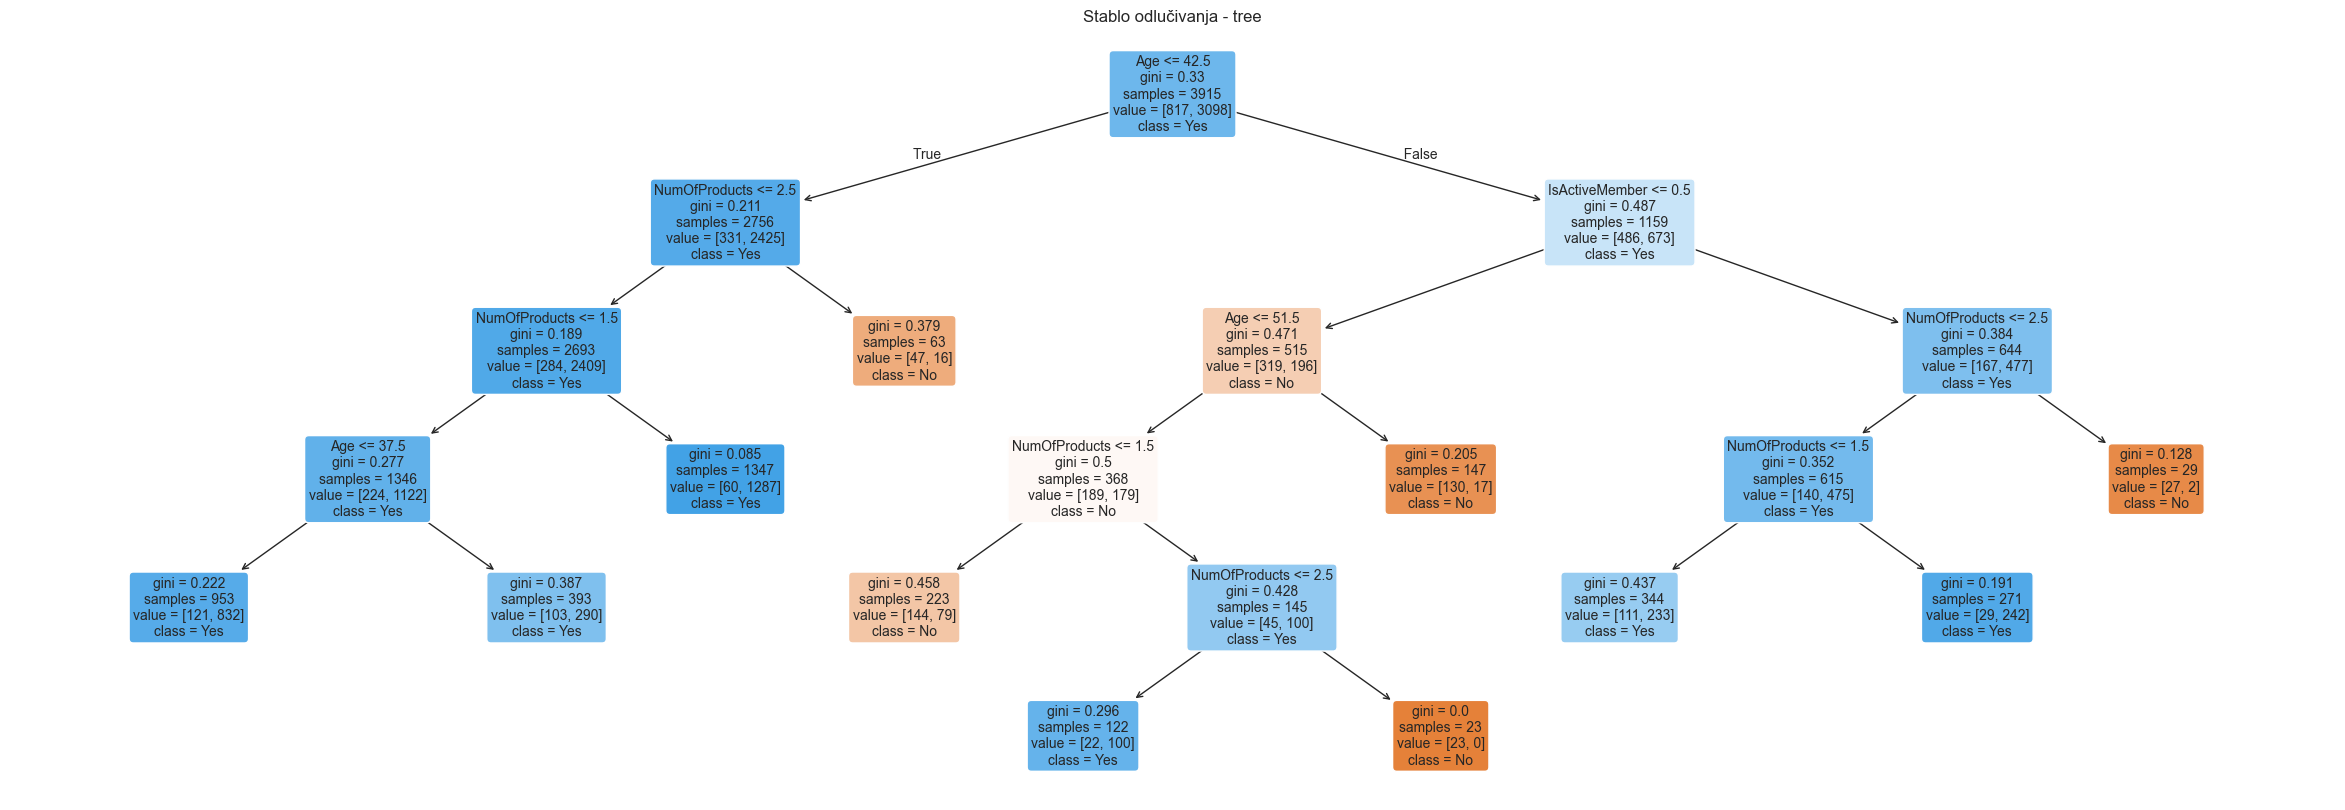

In [35]:
tree = DecisionTreeClassifier(ccp_alpha=best_ccp_alpha,random_state=42)
tree.fit(X_train, y_train)

# Vizualizacija stabla odlučivanja
plt.figure(figsize=[30,10])
plot_tree(tree,
          feature_names=X_train.columns,
          class_names=['No','Yes'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Stablo odlučivanja - tree")
plt.show()

In [36]:
# Kreiranje predikcije za test skup za tree
y_pred = tree.predict(X_test)

In [ ]:
y_pred = tree.predict(X_test)

### Kreiranje matrice konfuzije

In [37]:
cm = confusion_matrix(y_test, y_pred)
print("Matrica kofuzije:")
print(cm)

# Kreiraj DataFrame sa oznakama redova i kolona
cm_df = pd.DataFrame(cm,
                       index = ['Stvarno:No','Stvarno:Yes'],
                       columns = ['Predviđeno:No','Predviđeno:Yes'])
print(cm_df)

Matrica kofuzije:
[[ 92 112]
 [ 30 745]]
             Predviđeno:No  Predviđeno:Yes
Stvarno:No              92             112
Stvarno:Yes             30             745


In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
# disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels=['No','Yes'])
# disp.plot(cmap=plt.cm.Blues)
# plt.show()

44 vrednosti postoje u matrici konfuzije TP, TN, FP i FN:
True-Positive(TP) - koliko klijenata smo predvideli da će ostati u banci i oni su zaista ostali - 745
 True-Negative(TN) - koliko klijenata smo predvideli da će napustiti banku i oni su je zaista napustili - 92
 False-Positive(FP) - koliko klijenata smo predvideli da će ostati u banci, a oni su je ipak napustili - 112
 False-Negative(FN) - koliko klijenata smo predvideli da će napustiti banku, a oni su ipak ostali - 30

4 metrike se koriste za evaluaciju performansi klasifikacionog modela:
    Accuracy (tačnost) - procenat tačnih predikcija (i pozitivnih i negativnih);
    Precision (preciznost) - procenat tačno predviđenih pozitivnih predikcija u odnosu na sve pozitivne predikcije koje je model napravio;
    Recall (odziv) - procenat pozitivnih predikcija koje je model tačno identifikovao kao pozitivne u odnosu na ukupan broj stvarno pozitivnih;
    F1 - mera za balansiranje vrednosti precision-a i recall-a.

In [38]:
def compute_basic_eval_measures(cm, model_name=""):

    from pandas import Series

    TP = cm[1,1]
    TN = cm[0,0]
    FP = cm[0,1]
    FN = cm[1,0]

    accuracy = (TP + TN)/cm.sum()
    precision = TP/(TP + FP)
    recall = TP/(TP + FN)
    F1 = 2*precision*recall/(precision + recall)

    return Series(data=[accuracy, precision, recall, F1],
                  index=['accuracy', 'precision', 'recall', 'F1'],
                  name=model_name)

In [ ]:
def metrics(y_true, y_pred):
   accuracy= accuracy_score(y_true, y_pred)
   precision = precision_score(y_true, y_pred,pos_label=1)
   recall = recall_score(y_true, y_pred,pos_label=1)
   f1 = f1_score(y_true, y_pred,pos_label=1)
   return accuracy, precision, recall, f1


In [ ]:
ev = metrics(cm,'tree')
print(ev)

In [39]:
eval1 = compute_basic_eval_measures(cm, 'tree1')
eval1

accuracy     0.854954
precision    0.869312
recall       0.961290
F1           0.912990
Name: tree1, dtype: float64

accuracy - koliko tačno predviđamo izlaznu varijablu. Od 979 klijenata tačno je predviđeno 837, odnosno, za 85.5% klijenata je tačno predviđeno da li će ostati u banci ili ne.

precision - od svih klijenata predviđenih da će ostati banci, koji procenat klijenata je zaista ostao. Od svih klijenata za predviđenih da će ostati u banci, 87% njih je stvarno ostalo.

recall - od svih klijenata koji su zaista ostali u banci, koji procenat klijenata je predviđeno da će ostati u banci. Među svim klijentima koji su zaista ostali u banci, tačno je predviđeno 96%.

F1 - predstavlja meru performansi modela za balansirane vrednosti precision i recall. S obzirom da su recision i recall u antagonističkom odnosu, povećanje jedne dovodi do smanjenja druge i obrnuto.
Kako su i precision i recall visoki, vrednost ove metrike je visoka 0.91. U kontekstu zadatka, ova metrika pokazuje da nismo pravili mnogo grešaka predviđajući ostanak klijenata u banci.

**Napomena:** Prikazane interpretacije metrika i matrice konfuzije služe samo kao ilustracija jednog od mogućih načina i ne predstavljaju jedini ispravan način njihovog iznošenja u okviru zadatka.
